# Reconstruction accuracy across pLMs

Compare bVAE and pLM-bVAE models without hyperparameter optimization on Trastuzumab-scFv CDRH3 variants using exact reconstruction and BLOSUM62 scores.

In [1]:
# Compare sequence reconstruction accuracy across models for Trastuzumab-scFv CDRH3 variants.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load model outputs and test sequences

In [2]:
# Load test sequences and reconstructed sequences.
plm_res = "...\\pLM-bVAE\\reproduction_paper\\outputs\\"
plm_data = "...\\pLM-bVAE\\reproduction_paper\\data\\"
test_seqs = pd.read_csv(plm_data + "cdrh3\\bvae\\test.txt", sep="\t", header=None, names=["seqs"])
test_seqs["seqs"] = test_seqs["seqs"].str.replace(" ", "")
# bvae
dec_bvae = pd.read_csv(plm_res + "cdrh3_models\\bvae\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_bvae["seqs"] = dec_bvae["seqs"].str.replace(" ", "")
# esm_8m
dec_esm_8m = pd.read_csv(plm_res + "cdrh3_models\\esm_8m\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_esm_8m["seqs"] = dec_esm_8m["seqs"].str.replace(" ", "")
# esm_650m
dec_esm_650m = pd.read_csv(plm_res + "cdrh3_models\\esm_650m\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_esm_650m["seqs"] = dec_esm_650m["seqs"].str.replace(" ", "")
# esm_3b
dec_esm_3b = pd.read_csv(plm_res + "cdrh3_models\\esm_3b\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_esm_3b["seqs"] = dec_esm_3b["seqs"].str.replace(" ", "")
# prott5
dec_prott5 = pd.read_csv(plm_res + "cdrh3_models\\prott5\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_prott5["seqs"] = dec_prott5["seqs"].str.replace(" ", "")
# prostt5
dec_prostt5 = pd.read_csv(plm_res + "cdrh3_models\\prostt5\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_prostt5["seqs"] = dec_prostt5["seqs"].str.replace(" ", "")
# ankh_base
dec_ankh_base = pd.read_csv(plm_res + "cdrh3_models\\ankh_base\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_ankh_base["seqs"] = dec_ankh_base["seqs"].str.replace(" ", "")
# ankh_large
dec_ankh_large = pd.read_csv(plm_res + "cdrh3_models\\ankh_large\\model_output\\binary\\decoded.txt", sep="\t", header=None, names=["seqs"])
dec_ankh_large["seqs"] = dec_ankh_large["seqs"].str.replace(" ", "")

## Exact sequence reconstruction

In [3]:
# Calculate Levenshtein distances between test and decoded sequences.
import Levenshtein
def cal_levenshtein_dist(test_seqs, decoded_seqs):
    lev_distances = []
    for original, decoded in zip(test_seqs["seqs"], decoded_seqs["seqs"]):
        dist = Levenshtein.distance(original, decoded)
        lev_distances.append(dist)
    return lev_distances

In [4]:
# bvae
dist_bvae = cal_levenshtein_dist(test_seqs, dec_bvae)
# esm_8m
dist_esm_8m = cal_levenshtein_dist(test_seqs, dec_esm_8m)
# esm_650m
dist_esm_650m = cal_levenshtein_dist(test_seqs, dec_esm_650m)
# esm_3b
dist_esm_3b = cal_levenshtein_dist(test_seqs, dec_esm_3b)
# prott5
dist_prott5 = cal_levenshtein_dist(test_seqs, dec_prott5)
# prostt5
dist_prostt5 = cal_levenshtein_dist(test_seqs, dec_prostt5)
# ankh_base
dist_ankh_base = cal_levenshtein_dist(test_seqs, dec_ankh_base)
# ankh_large
dist_ankh_large = cal_levenshtein_dist(test_seqs, dec_ankh_large)

In [5]:
df_Levdist = pd.DataFrame({
    "distance": np.r_[dist_bvae, dist_esm_8m, dist_esm_650m, dist_esm_3b, dist_prott5, dist_prostt5, dist_ankh_base, dist_ankh_large],
    "model": (["bvae"] * len(dist_bvae)) + (["esm_8m"] * len(dist_esm_8m)) + (["esm_650m"] * len(dist_esm_650m)) + (["esm_3b"] * len(dist_esm_3b)) + (["prott5"] * len(dist_prott5)) + (["prostt5"] * len(dist_prostt5)) + (["ankh_base"] * len(dist_ankh_base)) + (["ankh_large"] * len(dist_ankh_large))
})

In [6]:
# Calculate the fraction of sequences with zero Levenshtein distance for each model.
df_Levdist_zero = df_Levdist[df_Levdist["distance"] == 0].groupby("model").size() / df_Levdist.groupby("model").size()
df_Levdist_zero = df_Levdist_zero.reset_index()
df_Levdist_zero.columns = ["model", "The ratio of seqs with Lev_dist of 0"]

# Set the model order.
df_Levdist_zero["model"] = pd.Categorical(df_Levdist_zero["model"], categories=["bvae", "esm_8m", "esm_650m", "esm_3b", "prott5", "prostt5", "ankh_base", "ankh_large"], ordered=True)
df_Levdist_zero = df_Levdist_zero.sort_values("model").reset_index(drop=True)

In [7]:
df_Levdist_zero

,model,The ratio of seqs with Lev_dist of 0
0,bvae,0.706250
1,esm_8m,0.862500
2,esm_650m,0.732292
3,esm_3b,0.540625
4,prott5,0.838542
5,prostt5,0.726042
6,ankh_base,0.776042
7,ankh_large,0.835417


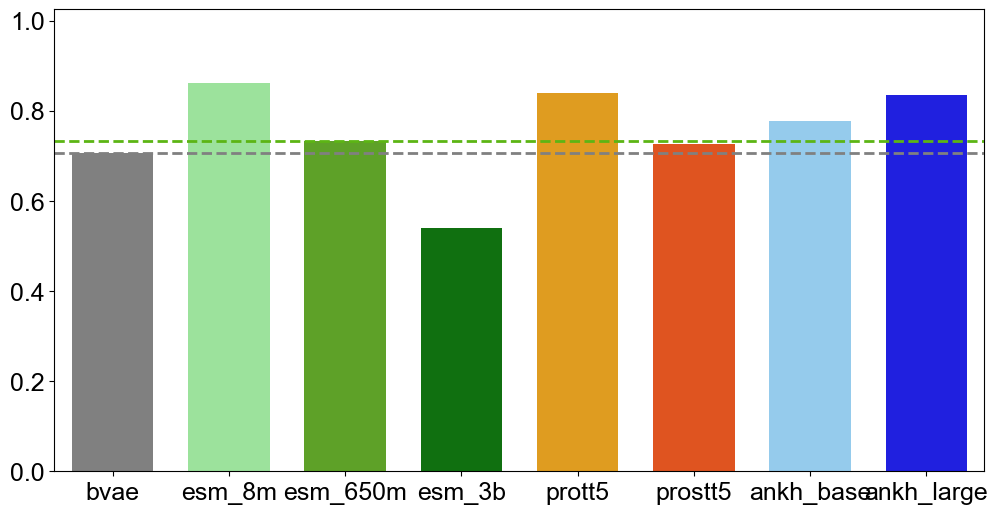

In [8]:
# Plot the fraction of exact reconstructions.
plt.figure(figsize=(12, 6))
sns.barplot(x="model", y="The ratio of seqs with Lev_dist of 0", data=df_Levdist_zero, palette=["gray", "lightgreen", "#5CB514", "green", "orange", "#ff4500", "lightskyblue", "blue"], width=0.7)
# Show the bVAE result as a horizontal reference line.
bvae_value = df_Levdist_zero[df_Levdist_zero["model"] == "bvae"]["The ratio of seqs with Lev_dist of 0"].values[0]
plt.axhline(y=bvae_value, color='gray', linestyle='--', linewidth=2)
# Show the ESM2 650M result as a horizontal reference line.
esm_650m_value = df_Levdist_zero[df_Levdist_zero["model"] == "esm_650m"]["The ratio of seqs with Lev_dist of 0"].values[0]
plt.axhline(y=esm_650m_value, color='#5CB514', linestyle='--', linewidth=2)

plt.ylim(0, 1.025)
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

## BLOSUM62 reconstruction accuracy

In [9]:
# Calculate BLOSUM62 scores.
from Bio.Align import PairwiseAligner, substitution_matrices

def cal_blosum62_score(test_seqs, decoded_seqs):
    aligner = PairwiseAligner(mode="global")
    aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
    aligner.open_gap_score = -10
    aligner.extend_gap_score = -0.5

    scores = []
    for original, decoded in zip(test_seqs["seqs"], decoded_seqs["seqs"]):
        # Calculate the score without constructing the alignment.
        score = aligner.score(original, decoded)
        scores.append(score)
    return scores

In [10]:
# Calculate BLOSUM62 scores.
# bvae
b62_bvae = cal_blosum62_score(test_seqs, dec_bvae)
# esm_8m
b62_esm_8m = cal_blosum62_score(test_seqs, dec_esm_8m)
# esm_650m
b62_esm_650m = cal_blosum62_score(test_seqs, dec_esm_650m)
# esm_3b
b62_esm_3b = cal_blosum62_score(test_seqs, dec_esm_3b)
# prott5
b62_prott5 = cal_blosum62_score(test_seqs, dec_prott5)
# prostt5
b62_prostt5 = cal_blosum62_score(test_seqs, dec_prostt5)
# ankh_base
b62_ankh_base = cal_blosum62_score(test_seqs, dec_ankh_base)
# ankh_large
b62_ankh_large = cal_blosum62_score(test_seqs, dec_ankh_large)

In [11]:
df_bs62 = pd.DataFrame({
    "score": np.r_[b62_bvae, b62_esm_8m, b62_esm_650m, b62_esm_3b, b62_prott5, b62_prostt5, b62_ankh_base, b62_ankh_large],
    "model": (["bvae"] * len(b62_bvae)) + (["esm_8m"] * len(b62_esm_8m)) + (["esm_650m"] * len(b62_esm_650m)) + (["esm_3b"] * len(b62_esm_3b)) + (["prott5"] * len(b62_prott5)) + (["prostt5"] * len(b62_prostt5)) + (["ankh_base"] * len(b62_ankh_base)) + (["ankh_large"] * len(b62_ankh_large))
})

In [12]:
# Calculate the 95th percentile of bVAE BLOSUM62 scores.
bvae_top5 = np.percentile(df_bs62[df_bs62["model"] == "bvae"]["score"], 95)
bvae_top5

np.float64(105.0)

In [13]:
def top_tail_global_threshold(
    df,
    score_col="score",
    model_col="model",
):
    rows = []

    # Calculate the upper-tail threshold for bVAE scores.
    threshold = bvae_top5

    for model, sub in df.groupby(model_col):
        scores = sub[score_col].dropna()
        n_total = len(scores)

        n_top = (scores >= threshold).sum()
        frac_top = n_top / n_total

        rows.append({
            "fraction_top": frac_top,
            "model": model
        })

    return pd.DataFrame(rows)

In [14]:
global_top_tail_df = top_tail_global_threshold(
    df_bs62,
    score_col="score",
    model_col="model",
)

# Rename the fraction column.
global_top_tail_df.rename(columns={"fraction_top": "The ratio of seqs with BLOSUM62 score in the top 5% of bvae"}, inplace=True)

# Reorder the columns.
global_top_tail_df = global_top_tail_df[["model", "The ratio of seqs with BLOSUM62 score in the top 5% of bvae"]]

# Set the model order.
model_order = ["bvae", "esm_8m", "esm_650m", "esm_3b", "prott5", "prostt5", "ankh_base", "ankh_large"]
global_top_tail_df["model"] = pd.Categorical(global_top_tail_df["model"], categories=model_order, ordered=True)
global_top_tail_df = global_top_tail_df.sort_values("model").reset_index(drop=True)

In [15]:
global_top_tail_df 

,model,The ratio of seqs with BLOSUM62 score in the top 5% of bvae
0,bvae,0.054167
1,esm_8m,0.058333
2,esm_650m,0.047917
3,esm_3b,0.038542
4,prott5,0.056250
5,prostt5,0.054167
6,ankh_base,0.052083
7,ankh_large,0.058333


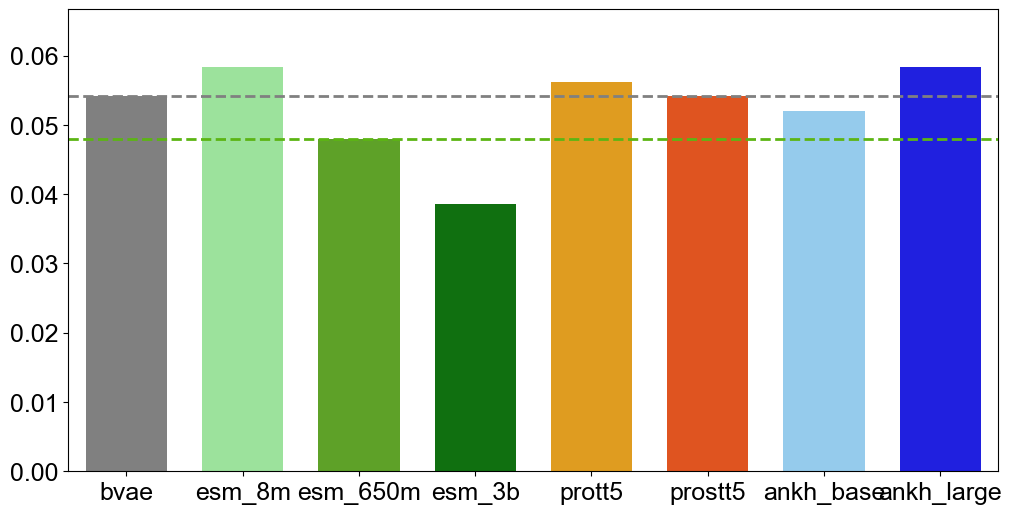

In [16]:
# Plot the fractions above the bVAE BLOSUM62 threshold.
plt.figure(figsize=(12, 6))
sns.barplot(x="model", y="The ratio of seqs with BLOSUM62 score in the top 5% of bvae", data=global_top_tail_df, palette=["gray", "lightgreen", "#5CB514", "green", "orange", "#ff4500", "lightskyblue", "blue"], width=0.7)
# Show the bVAE result as a horizontal reference line.
bvae_value = global_top_tail_df[global_top_tail_df["model"] == "bvae"]["The ratio of seqs with BLOSUM62 score in the top 5% of bvae"].values[0]
plt.axhline(y=bvae_value, color='gray', linestyle='--', linewidth=2)
# Show the ESM2 650M result as a horizontal reference line.
esm_650m_value = global_top_tail_df[global_top_tail_df["model"] == "esm_650m"]["The ratio of seqs with BLOSUM62 score in the top 5% of bvae"].values[0]
plt.axhline(y=esm_650m_value, color='#5CB514', linestyle='--', linewidth=2)

plt.ylim(0, 0.0667)
plt.xlabel('')
plt.ylabel('')
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()